# Length-normalized mutation frequencies
### Pick **any** cBioPortal study and compare raw vs CDS-length-normalized mutation frequency

**MSK CBSP Hackathon 2026 — team veggenes**

Longer genes accumulate more mutations simply because they present a bigger target, so a raw "% of samples mutated" ranking is biased toward big genes. This notebook:

1. Lets you **choose a study** (search by keyword, or use the dropdown).
2. **Extracts** per-gene mutation frequency.
3. **Fetches gene lengths** (canonical **CDS** length) from **Ensembl**.
4. **Normalizes** frequency by CDS length and shows raw vs normalized rankings.

**A note on how we fetch the data.** The hackathon intro notebook pulls *every* mutation with
`Mutations.getMutationsInMolecularProfileBySampleListIdUsingGET(..., projection='DETAILED')` and counts them
with pandas. On the **current** public cBioPortal API that GET now *requires* an `entrezGeneId` (you get
`Request parameter is missing: entrezGeneId` otherwise — the `cancer-type-summary` hackathon notebook always
passes one), and fetching all mutations un-paged 503s on large/high-TMB cohorts. So instead we use cBioPortal's
**study-view `mutated-genes` endpoint** — the same aggregated data that powers the *Mutated Genes* table in the
study view (the `# Mut` / `#` / `Freq` columns). One small, fast, robust request per study, for any study size.

APIs: [cBioPortal REST](https://www.cbioportal.org/api) and [Ensembl REST](https://rest.ensembl.org), both via `requests`.

In [1]:
# First run only (uncomment). On the 'veggenes' conda kernel these are already installed.
# !pip install pandas matplotlib seaborn requests ipywidgets

from IPython.display import display
import requests, time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("white")
sns.set_context("notebook")

# ---- Defaults (override per run) -----------------------------------
STUDY_ID = "luad_mskimpact_2021"   # default study; change it or use the picker below
TOP_N    = 100                      # keep the top-N most frequently mutated genes
CBIO     = "https://www.cbioportal.org/api"
ENSEMBL  = "https://rest.ensembl.org"
JSON_HDR = {"Accept": "application/json", "Content-Type": "application/json"}
# --------------------------------------------------------------------

## 1. Choose a study

`find_studies(keyword)` searches all cBioPortal studies (by name or id) and returns the matches, sorted by size. Use it to discover the `studyId` you want.

In [2]:
def find_studies(keyword=""):
    """Return a DataFrame of studies whose name or id matches `keyword`."""
    studies = requests.get(f"{CBIO}/studies", params={"projection": "SUMMARY"},
                           headers={"Accept": "application/json"}, timeout=60).json()
    df = pd.DataFrame(studies)
    if keyword:
        k = keyword.lower()
        df = df[df["name"].str.lower().str.contains(k)
                | df["studyId"].str.lower().str.contains(k)]
    cols = ["studyId", "name", "allSampleCount", "cancerTypeId"]
    df = df[[c for c in cols if c in df.columns]].copy()
    return df.sort_values("allSampleCount", ascending=False).reset_index(drop=True)

# Example: all lung studies
find_studies("lung").head(20)

,studyId,name,allSampleCount,cancerTypeId
0,luad_mskcc_2023_met_organotropism,"Lung Adenocarcinoma Met Organotropism (MSK, Ca...",2653,luad
1,nsclc_ctdx_msk_2022,"Metastatic Non-Small Cell Lung Cancer (MSK, Na...",2621,nsclc
2,nsclc_tcga_broad_2016,"Pan-Lung Cancer (TCGA, Nat Genet 2016)",1144,nsclc
3,lung_msk_2017,"Non-Small Cell Cancer (MSK, Cancer Discov 2017)",915,luad
4,luad_mskcc_2020,"Lung Adenocarcinoma (MSK, J Thorac Oncol 2020)",604,luad
5,luad_tcga,"Lung Adenocarcinoma (TCGA, Firehose Legacy)",586,luad
6,luad_tcga_gdc,"Lung Adenocarcinoma (TCGA GDC, 2025)",571,luad
7,luad_tcga_pan_can_atlas_2018,"Lung Adenocarcinoma (TCGA, PanCancer Atlas)",566,luad
8,lusc_tcga,"Lung Squamous Cell Carcinoma (TCGA, Firehose L...",511,lusc
9,lusc_tcga_gdc,"Lung Squamous Cell Carcinoma (TCGA GDC, 2025)",503,lusc


### Optional: pick the study from a dropdown

Set `SEARCH` to any keyword (e.g. `"lung"`, `"melanoma"`, `"msk"`, `"tcga"`). Run the cell, choose from the dropdown, and the selection is stored in `STUDY_ID`. If `ipywidgets` isn't available, just set `STUDY_ID` by hand.

In [ ]:
SEARCH = "lung"   # <- keyword to populate the dropdown

try:
    import ipywidgets as widgets
    _opts_df = find_studies(SEARCH)
    _options = [(f"{r['name']}  ({r.studyId}, n={r.allSampleCount})", r.studyId)
                for _, r in _opts_df.iterrows()]
    _dd = widgets.Dropdown(options=_options, description="Study:",
                           layout=widgets.Layout(width="90%"))
    def _on_change(change):
        global STUDY_ID
        if change["name"] == "value":
            STUDY_ID = change["new"]
            print("STUDY_ID =", STUDY_ID)
    _dd.observe(_on_change)
    STUDY_ID = _dd.value          # initialise to the first option
    display(_dd)
    print("STUDY_ID =", STUDY_ID, "  (change the dropdown to update)")
except ImportError:
    print("ipywidgets not installed -- set STUDY_ID manually, e.g. STUDY_ID = 'luad_tcga_pub'")

## 2. Mutation frequency per gene (for any study)

`get_mutation_frequencies` calls the study-view `mutated-genes` endpoint and returns, per gene:

* **`altered_samples`** — distinct samples mutated in the gene (the `#` column).
* **`total_mutations`** — total mutation events (the `# Mut` column; a sample mutated twice counts twice).
* **`profiled`** — samples profiled for that gene (the `Freq` denominator).
* **`freq_pct`** — `altered_samples / profiled` × 100.

These are exactly the numbers shown in the cBioPortal study-view *Mutated Genes* table.

In [3]:
def get_mutation_frequencies(study_id, top_n=None):
    r = requests.post(f"{CBIO}/mutated-genes/fetch", headers=JSON_HDR,
                      json={"studyIds": [study_id]}, timeout=120)
    r.raise_for_status()
    data = r.json()
    if not data:
        raise ValueError(f"No mutation data returned for study '{study_id}'.")

    freq = pd.DataFrame([{
        "hugoGeneSymbol":  g["hugoGeneSymbol"],
        "altered_samples": g["numberOfAlteredCases"],   # '#'      column
        "total_mutations": g["totalCount"],             # '# Mut'  column
        "profiled":        g["numberOfProfiledCases"],  # 'Freq'   denominator
    } for g in data]).set_index("hugoGeneSymbol")

    freq["freq_pct"] = 100 * freq["altered_samples"] / freq["profiled"]
    freq = freq.sort_values("altered_samples", ascending=False)

    n_profiled = int(freq["profiled"].max())
    freq.attrs["study_id"] = study_id
    freq.attrs["n_profiled"] = n_profiled
    print(f"{study_id}: {len(freq)} mutated genes across up to {n_profiled} profiled samples.")
    return freq.head(top_n) if top_n else freq

get_mutation_frequencies(STUDY_ID, top_n=15)

luad_mskimpact_2021: 230 mutated genes across up to 186 profiled samples.


,altered_samples,total_mutations,profiled,freq_pct
hugoGeneSymbol,,,,
EGFR,183,240,186,98.387097
TP53,128,135,186,68.817204
PIK3CA,20,21,186,10.752688
RB1,19,19,186,10.215054
CTNNB1,18,18,186,9.677419
RBM10,14,14,186,7.526882
PTEN,13,13,186,6.989247
ARID1A,10,12,186,5.376344
PTPRD,9,9,186,4.838710


## 3. Canonical CDS length from Ensembl (for any gene set)

In [4]:
def _ensembl_post(path, payload, params=None):
    r = requests.post(f"{ENSEMBL}{path}", headers=JSON_HDR,
                      params=params or {}, json=payload, timeout=60)
    r.raise_for_status()
    return r.json()

def _chunks(seq, n):
    for i in range(0, len(seq), n):
        yield seq[i:i + n]

def get_cds_lengths(genes, seq_type="cds"):
    """Map Hugo symbols -> canonical-transcript CDS length (bp). seq_type='protein' for aa."""
    # symbol -> canonical transcript id (version stripped)
    canonical = {}
    for batch in _chunks(list(genes), 50):
        res = _ensembl_post("/lookup/symbol/homo_sapiens", {"symbols": batch})
        for sym, info in res.items():
            ct = info.get("canonical_transcript")
            if ct:
                canonical[sym] = ct.split(".")[0]
        time.sleep(0.2)

    # transcript id -> sequence length
    tx_to_genes = {}
    for sym, tx in canonical.items():
        tx_to_genes.setdefault(tx, []).append(sym)
    lengths = {}
    for batch in _chunks(list(tx_to_genes), 50):
        res = _ensembl_post("/sequence/id", {"ids": batch}, params={"type": seq_type})
        for rec in res:
            for sym in tx_to_genes[rec["query"]]:
                lengths[sym] = len(rec["seq"])
        time.sleep(0.2)

    missing = sorted(set(genes) - set(lengths))
    if missing:
        print(f"No CDS length for {len(missing)} gene(s): {missing}")
    return lengths

## 4. End-to-end: `analyze(study_id)`

Combines the steps, computes the normalized metrics, draws the plots, and returns the per-gene DataFrame.

* **`freq_per_kb`** = `freq_pct / cds_kb` — headline length-normalized frequency.
* **`mut_per_sample_per_kb`** = `(total_mutations / profiled) / cds_kb` — mutation-density view.

In [5]:
def analyze(study_id, top_n=TOP_N, plot=True):
    freq = get_mutation_frequencies(study_id, top_n=top_n)
    n_profiled = freq.attrs["n_profiled"]

    top = freq.copy()
    top["cds_bp"] = pd.Series(get_cds_lengths(top.index.tolist()))
    top = top.dropna(subset=["cds_bp"]).copy()
    top["cds_kb"] = top["cds_bp"] / 1000.0
    top["freq_per_kb"] = top["freq_pct"] / top["cds_kb"]
    top["mut_per_sample_per_kb"] = (top["total_mutations"] / top["profiled"]) / top["cds_kb"]
    top.attrs.update(freq.attrs)

    if plot:
        _plot_compare(top, study_id, n_profiled)
        _plot_scatter(top, study_id)
    return top


def _plot_compare(top, study_id, n, k=15):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    top.sort_values("freq_pct", ascending=False).head(k)["freq_pct"].plot(
        kind="bar", color="#4C72B0", ax=axes[0])
    axes[0].set_title(f"UNNORMALIZED\n{study_id} (n={n})")
    axes[0].set_ylabel("% samples mutated"); axes[0].set_xlabel("")
    top.sort_values("freq_per_kb", ascending=False).head(k)["freq_per_kb"].plot(
        kind="bar", color="#C44E52", ax=axes[1])
    axes[1].set_title(f"LENGTH-NORMALIZED (per kb CDS)\n{study_id} (n={n})")
    axes[1].set_ylabel("% samples mutated per kb CDS"); axes[1].set_xlabel("")
    for ax in axes:
        ax.tick_params(axis="x", rotation=300)
    sns.despine(); plt.tight_layout(); plt.show()


def _plot_scatter(top, study_id, label_n=8):
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.scatter(top["cds_kb"], top["freq_pct"], s=25, color="#55A868", alpha=0.7)
    slope = top["freq_pct"].sum() / top["cds_kb"].sum()
    xs = [0, top["cds_kb"].max()]
    ax.plot(xs, [slope * x for x in xs], "--", color="gray", label="expected ∝ CDS length")
    resid = top["freq_pct"] - slope * top["cds_kb"]
    for g in resid.sort_values(ascending=False).head(label_n).index:
        ax.annotate(g, (top.loc[g, "cds_kb"], top.loc[g, "freq_pct"]),
                    fontsize=9, xytext=(4, 3), textcoords="offset points")
    ax.set_xlabel("Canonical CDS length (kb)"); ax.set_ylabel("% samples mutated")
    ax.set_title(f"Mutation frequency vs gene length — {study_id}")
    ax.legend(); sns.despine(); plt.tight_layout(); plt.show()

### Run it on the selected study

luad_mskimpact_2021: 230 mutated genes across up to 186 profiled samples.


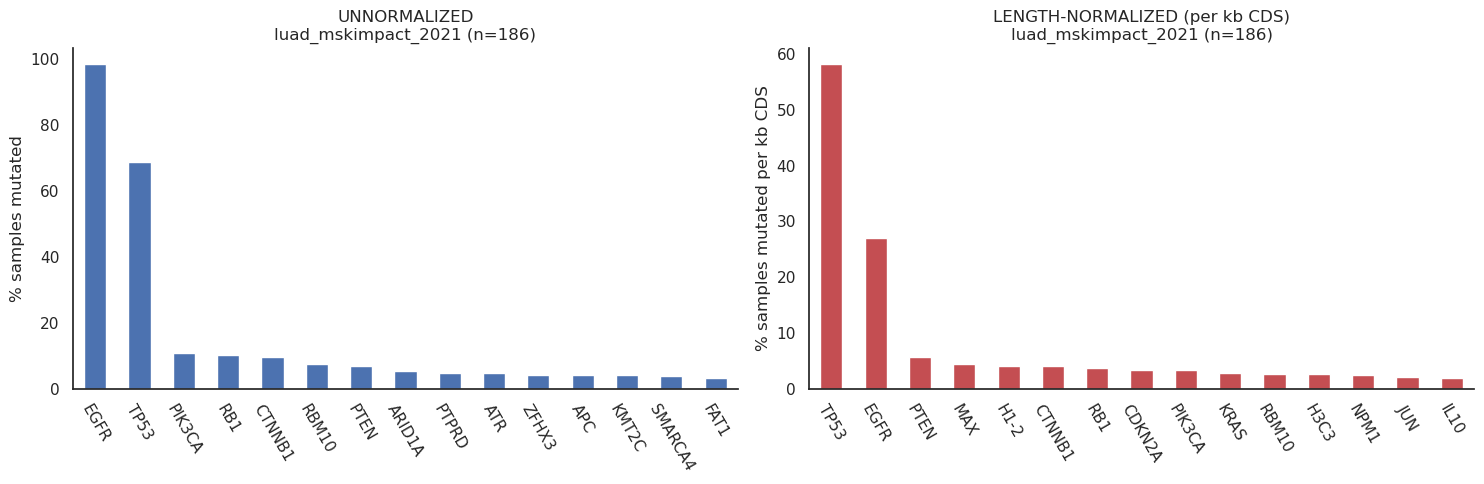

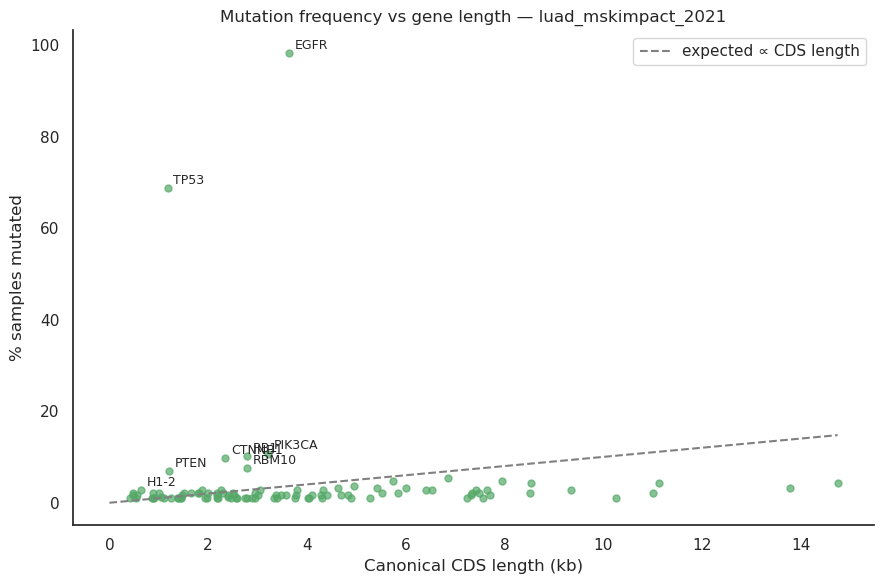

,altered_samples,total_mutations,profiled,freq_pct,cds_bp,cds_kb,freq_per_kb,mut_per_sample_per_kb
hugoGeneSymbol,,,,,,,,
EGFR,183,240,186,98.387097,3633,3.633,27.081502,0.355167
TP53,128,135,186,68.817204,1182,1.182,58.220985,0.614049
PIK3CA,20,21,186,10.752688,3207,3.207,3.352881,0.035205
RB1,19,19,186,10.215054,2787,2.787,3.665251,0.036653
CTNNB1,18,18,186,9.677419,2346,2.346,4.125072,0.041251
RBM10,14,14,186,7.526882,2793,2.793,2.694909,0.026949
PTEN,13,13,186,6.989247,1212,1.212,5.766706,0.057667
ARID1A,10,12,186,5.376344,6858,6.858,0.783952,0.009407
PTPRD,9,9,186,4.838710,5739,5.739,0.843128,0.008431


In [6]:
result = analyze(STUDY_ID, TOP_N)
result.head(15)

### Who moved most after normalization?

In [7]:
def rank_changes(top):
    c = top.assign(
        rank_raw=top["freq_pct"].rank(ascending=False, method="min").astype(int),
        rank_norm=top["freq_per_kb"].rank(ascending=False, method="min").astype(int))
    c["rank_change"] = c["rank_raw"] - c["rank_norm"]   # +ve = climbed after normalizing
    return c[["freq_pct", "cds_bp", "freq_per_kb", "rank_raw", "rank_norm", "rank_change"]]

rc = rank_changes(result)
print("Biggest CLIMBERS (compact, recurrently mutated):")
display(rc.sort_values("rank_change", ascending=False).head(10).round(2))
print("\nBiggest FALLERS (long genes, likely passengers):")
display(rc.sort_values("rank_change").head(10).round(2))

Biggest CLIMBERS (compact, recurrently mutated):


,freq_pct,cds_bp,freq_per_kb,rank_raw,rank_norm,rank_change
hugoGeneSymbol,,,,,,
IL10,1.08,537,2.00,73,15,58
H3C3,1.08,411,2.63,68,12,56
CCND2,1.08,870,1.24,73,19,54
CCND3,1.08,879,1.22,73,20,53
ICOSLG,1.08,909,1.18,73,23,50
CDKN2A,1.61,471,3.42,53,8,45
KRAS,1.61,567,2.84,53,10,43
CYSLTR2,1.18,1041,1.13,66,25,41
HLA-A,1.08,1098,0.98,68,29,39



Biggest FALLERS (long genes, likely passengers):


,freq_pct,cds_bp,freq_per_kb,rank_raw,rank_norm,rank_change
hugoGeneSymbol,,,,,,
FAT1,3.23,13767,0.23,15,92,-77
KMT2C,4.30,14736,0.29,12,84,-72
MGA,2.70,9345,0.29,19,85,-66
SPEN,2.15,10995,0.20,31,97,-66
NF1,2.15,8520,0.25,31,90,-59
ZFHX3,4.32,11112,0.39,11,70,-59
MTOR,2.69,7650,0.35,21,79,-58
NOTCH2,2.69,7416,0.36,21,78,-57
ATRX,2.15,7479,0.29,31,86,-55


## (Optional) Compare two studies side by side

Because the pipeline is a function, you can run it on several cohorts and compare. A targeted panel (MSK-IMPACT) vs a whole-exome cohort (TCGA) makes the length bias obvious — the big passenger genes (TTN, MUC16 …) only exist in the exome data.

In [ ]:
# Uncomment to compare. (Each call hits the APIs, so it takes a little while.)
# a = analyze("luad_mskimpact_2021", TOP_N, plot=False)   # MSK-IMPACT (targeted panel)
# b = analyze("luad_tcga_pub",       TOP_N, plot=False)   # TCGA LUAD (whole exome)
#
# merged = (a[["freq_pct", "freq_per_kb"]].add_suffix("_msk")
#           .join(b[["freq_pct", "freq_per_kb"]].add_suffix("_tcga"), how="outer"))
# merged.sort_values("freq_per_kb_tcga", ascending=False).head(20).round(2)

## Notes & caveats

* **Data source.** We use cBioPortal's study-view `mutated-genes` endpoint (the *Mutated Genes* table), not the hackathon intro's fetch-all-mutations GET — that GET now requires an `entrezGeneId` on the live API and 503s on large cohorts. The aggregated endpoint is fast and works for any study size.
* **Any study works** — use `find_studies("...")` to get an id, set `STUDY_ID`, rerun `analyze`.
* **Panel vs exome.** Targeted panels (MSK-IMPACT) omit giant passenger genes, so the length bias is milder than in whole-exome cohorts (TCGA). Compare them with the cell above.
* **CDS choice.** We use the Ensembl *canonical* transcript CDS. Pass `seq_type="protein"` to `get_cds_lengths` to normalize by amino acids (≈ CDS/3) instead.
* **Model.** `freq_per_kb` is a first-order, length-only correction — not a full background-mutation model (cf. MutSigCV, which also models per-base rate and sequence context).
* **`TOP_N`** controls how many genes flow through length lookup and plotting.